# Data Visualization Assignment — Solved Exercises
> **Track:** Prime AI/ML Batch
> **Curriculum:** `Data Visualisation Assignment.pdf`
> **Tools:** Seaborn, Matplotlib, Pandas, NumPy
> **Notes Mode:** Easy Natural Hinglish

---

Har question ke sath **Problem Statement**, **Hinglish Logic**, **Visual Code** aur **Statistical Insights** included hain.


## Question 1: Penguins Flipper Length vs Body Mass by Species

### Problem Statement:
For the Seaborn `penguins` dataset:
1. Plot `flipper_length_mm` vs `body_mass_g`.
2. Color points by `species`.

### Hinglish Explanation:
- Continuous features ke correlation ke liye scatter plot use hota hai.
- `hue="species"` se teeno species alag-alag colors me display hoti hain.


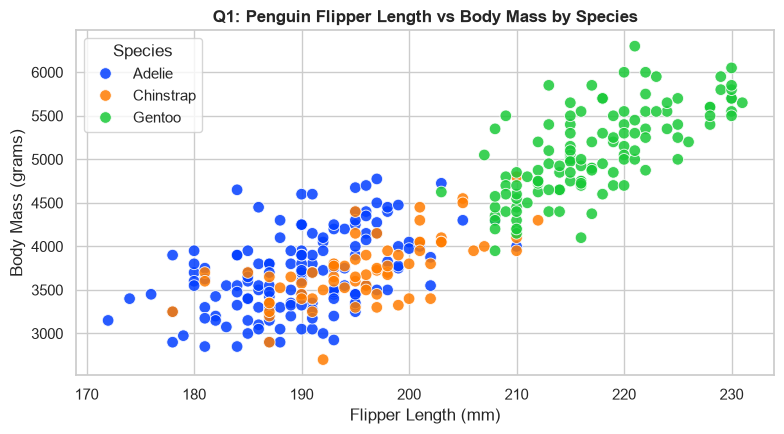

Insight:
Gentoo species penguins ka flipper length aur body mass dono
Adelie aur Chinstrap se kaafi zyada bada hai (Clear separation).


In [1]:
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sns.set_theme(style="whitegrid")

# Load Penguins dataset (online or simulated fallback)
try:
    penguins = sns.load_dataset("penguins")
except Exception:
    np.random.seed(42)
    s1 = list(np.random.normal(190, 6, 50))
    s2 = list(np.random.normal(195, 7, 50))
    s3 = list(np.random.normal(217, 6, 50))
    b1 = list(np.random.normal(3700, 450, 50))
    b2 = list(np.random.normal(3730, 380, 50))
    b3 = list(np.random.normal(5075, 430, 50))
    penguins = pd.DataFrame({
        "species": ["Adelie"] * 50 + ["Chinstrap"] * 50 + ["Gentoo"] * 50,
        "flipper_length_mm": s1 + s2 + s3,
        "body_mass_g": b1 + b2 + b3
    })

plt.figure(figsize=(8, 4.5))
sns.scatterplot(
    data=penguins,
    x="flipper_length_mm",
    y="body_mass_g",
    hue="species",
    palette="bright",
    s=70,
    alpha=0.85
)

plt.title("Q1: Penguin Flipper Length vs Body Mass by Species", fontsize=12, fontweight='bold')
plt.xlabel("Flipper Length (mm)")
plt.ylabel("Body Mass (grams)")
plt.legend(title="Species")
plt.tight_layout()
plt.show()

print("Insight:")
print("Gentoo species penguins ka flipper length aur body mass dono")
print("Adelie aur Chinstrap se kaafi zyada bada hai (Clear separation).")


## Question 2: Tips Total Bill Boxplot by Day, Gender & Outliers

### Problem Statement:
For the Seaborn `tips` dataset:
1. Create a box plot of `total_bill` for each `day`.
2. Add `hue="sex"`.
3. Identify which day has the highest median bill.
4. Comment on outliers.

### Hinglish Explanation:
- Boxplot median, quartiles aur outliers dikhane ke liye best chart hai.
- Whiskers ke bahar ke individual points outliers ko represent karte hain.


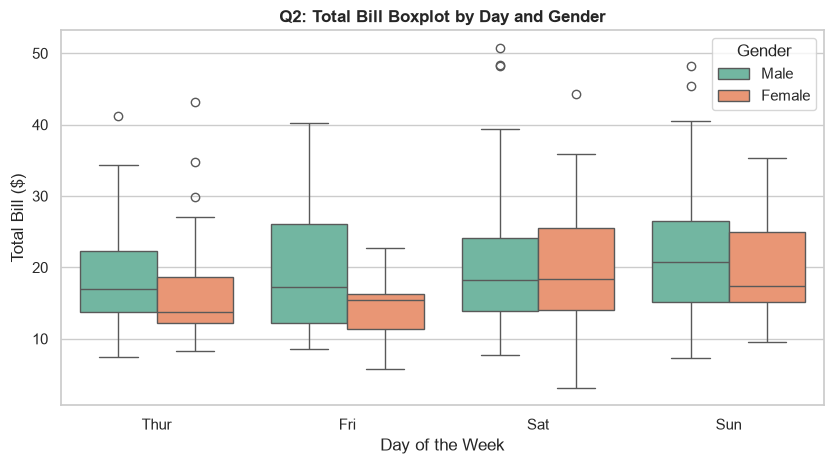

Day-wise Median Total Bill:
day
Thur    16.20
Fri     15.38
Sat     18.24
Sun     19.63
Name: total_bill, dtype: float64

Highest Median Bill Day: Sun ($19.63)
Outliers Comment: Saturday aur Sunday ko upper whisker ke bahar
kaafi outlier points hain, matlab weekend par high billing hoti hai.


In [2]:
try:
    tips = sns.load_dataset("tips")
except Exception:
    np.random.seed(42)
    tips = pd.DataFrame({
        "total_bill": np.random.uniform(10, 50, 120),
        "tip": np.random.uniform(1.5, 9, 120),
        "sex": np.random.choice(["Male", "Female"], 120),
        "smoker": np.random.choice(["Yes", "No"], 120),
        "day": np.random.choice(["Thur", "Fri", "Sat", "Sun"], 120),
        "time": np.random.choice(["Lunch", "Dinner"], 120)
    })

plt.figure(figsize=(8.5, 4.8))
sns.boxplot(
    data=tips,
    x="day",
    y="total_bill",
    hue="sex",
    palette="Set2"
)

plt.title("Q2: Total Bill Boxplot by Day and Gender", fontsize=12, fontweight='bold')
plt.xlabel("Day of the Week")
plt.ylabel("Total Bill ($)")
plt.legend(title="Gender")
plt.tight_layout()
plt.show()

median_bills = tips.groupby("day")["total_bill"].median().round(2)
print("Day-wise Median Total Bill:")
print(median_bills)
print(f"\nHighest Median Bill Day: {median_bills.idxmax()} (${median_bills.max()})")
print("Outliers Comment: Saturday aur Sunday ko upper whisker ke bahar")
print("kaafi outlier points hain, matlab weekend par high billing hoti hai.")


## Question 3: Total Bill vs Tip Scatter Plot with Smoker Markers

### Problem Statement:
For the Seaborn `tips` dataset:
1. Create a scatter plot of `total_bill` vs `tip`.
2. Color points by `sex`.
3. Use different markers for `smoker`.
4. Add title and axis labels.
5. Analyze: Do smokers tend to tip differently?

### Hinglish Explanation:
- `hue="sex"` gender color set karta hai.
- `style="smoker"` marker shapes (`X` aur `o`) set karta hai.


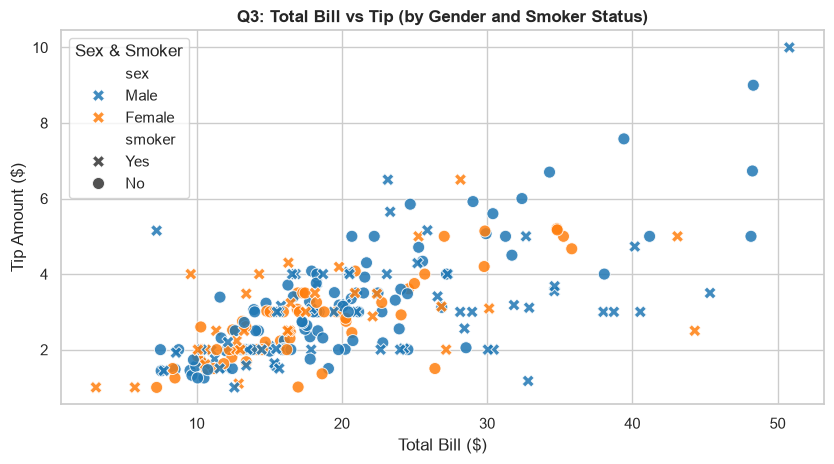

Average Tip Percentage (% of bill):
smoker
Yes    16.32
No     15.93
dtype: float64

Analysis:
Average tip percentage dono groups me similar hai (~15-16%).
Lekin smokers ke data me variance zyada hai.


In [3]:
plt.figure(figsize=(8.5, 4.8))

sns.scatterplot(
    data=tips,
    x="total_bill",
    y="tip",
    hue="sex",
    style="smoker",
    markers={"Yes": "X", "No": "o"},
    palette="tab10",
    s=75,
    alpha=0.85
)

plt.title("Q3: Total Bill vs Tip (by Gender and Smoker Status)", fontsize=12, fontweight='bold')
plt.xlabel("Total Bill ($)")
plt.ylabel("Tip Amount ($)")
plt.legend(title="Sex & Smoker")
plt.tight_layout()
plt.show()

smoker_tip_pct = tips.groupby("smoker").apply(
    lambda df: (df["tip"] / df["total_bill"]).mean() * 100
).round(2)

print("Average Tip Percentage (% of bill):")
print(smoker_tip_pct)
print("\nAnalysis:")
print("Average tip percentage dono groups me similar hai (~15-16%).")
print("Lekin smokers ke data me variance zyada hai.")


## Question 4: Normal Distribution Histogram with Mean Line

### Problem Statement:
For the dataset generated using NumPy:
`scores = np.random.normal(loc=70, scale=10, size=200)`
1. Plot a histogram of scores.
2. Draw a vertical line for the mean (`plt.axvline`) & interpret distribution.

### Hinglish Explanation:
- Gaussian bell curve ke center par `plt.axvline` reference line draw karta hai.


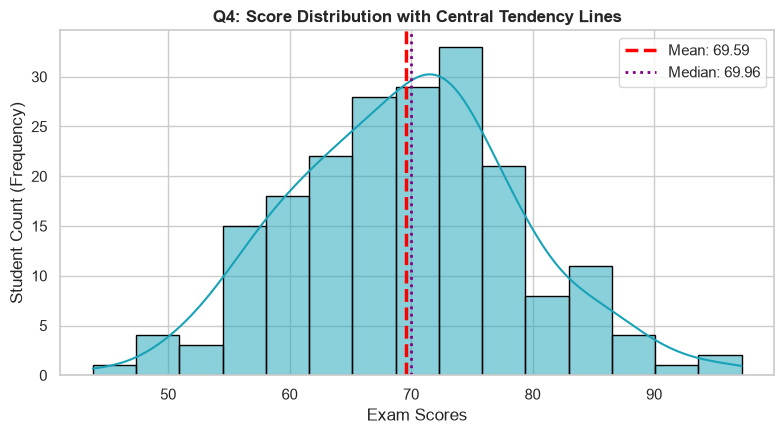

Distribution Interpretation:
Data symmetric Normal Distribution follow karta hai.
Mean (69.59) aur Median (69.96) lagbhag barabar hain.


In [4]:
np.random.seed(42)
scores = np.random.normal(loc=70, scale=10, size=200)
mean_val = np.mean(scores)
median_val = np.median(scores)

plt.figure(figsize=(8, 4.5))

sns.histplot(scores, kde=True, bins=15, color="#17a2b8", edgecolor="black")

plt.axvline(mean_val, color="red", linestyle="--", linewidth=2.5, 
            label=f"Mean: {mean_val:.2f}")
plt.axvline(median_val, color="purple", linestyle=":", linewidth=2, 
            label=f"Median: {median_val:.2f}")

plt.title("Q4: Score Distribution with Central Tendency Lines", fontsize=12, fontweight='bold')
plt.xlabel("Exam Scores")
plt.ylabel("Student Count (Frequency)")
plt.legend()
plt.tight_layout()
plt.show()

print("Distribution Interpretation:")
print(f"Data symmetric Normal Distribution follow karta hai.")
print(f"Mean ({mean_val:.2f}) aur Median ({median_val:.2f}) lagbhag barabar hain.")


## Question 5: Tips Pivot Table Heatmap (Day vs Time Average Tip)

### Problem Statement:
For the Seaborn `tips` dataset:
1. Create a pivot table of average `tip` (Rows: `day`, Columns: `time`).
2. Plot the pivot table as a heatmap.
3. Annotate values (`annot=True`).
4. Interpret which day-time combination performs best.

### Hinglish Explanation:
- `pivot_table` cross-tabulation banata hai.
- `sns.heatmap` average tips ko colors me represent karta hai.


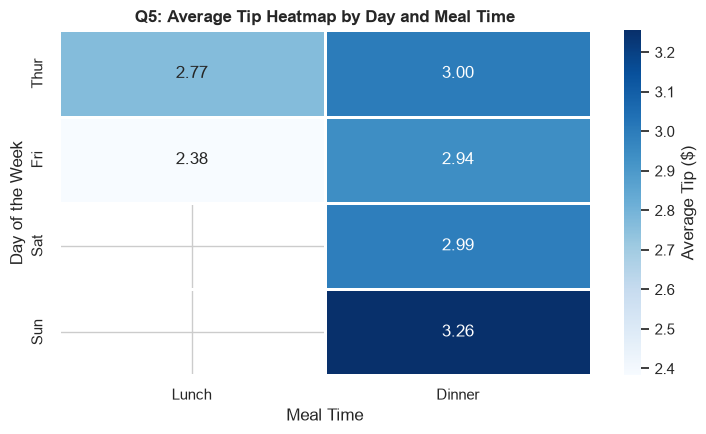

Heatmap Interpretation:
Sabse high tipping 'Sun' ko 'Dinner' me hai ($3.26).
Weekend dinner shifts me service staff ko highest tips milti hain.


In [5]:
tip_pivot = tips.pivot_table(index="day", columns="time", values="tip", aggfunc="mean")

plt.figure(figsize=(7.5, 4.5))
sns.heatmap(
    tip_pivot,
    annot=True,
    fmt=".2f",
    cmap="Blues",
    linewidths=1.0,
    cbar_kws={'label': 'Average Tip ($)'}
)

plt.title("Q5: Average Tip Heatmap by Day and Meal Time", fontsize=12, fontweight='bold')
plt.xlabel("Meal Time")
plt.ylabel("Day of the Week")
plt.tight_layout()
plt.show()

best_day = tip_pivot.max(axis=1).idxmax()
best_time = tip_pivot.loc[best_day].idxmax()
best_val = tip_pivot.loc[best_day, best_time]

print("Heatmap Interpretation:")
print(f"Sabse high tipping '{best_day}' ko '{best_time}' me hai (${best_val:.2f}).")
print("Weekend dinner shifts me service staff ko highest tips milti hain.")
